# Part 4, Topic 3: ChipWhisperer Analyzer CPA Attack (MAIN)


---
NOTE: This lab references some (commercial) training material on [ChipWhisperer.io](https://www.ChipWhisperer.io). You can freely execute and use the lab per the open-source license (including using it in your own courses if you distribute similarly), but you must maintain notice about this source location. Consider joining our training course to enjoy the full experience.

---

**SUMMARY:** *Last time, we saw how correlation can be used to recover an AES key, as well as the effectiveness of such an attack. In this lab, we'll repeat the attack with ChipWhisperer Analyzer and gain some additional information about the attack*

**LEARNING OUTCOMES:**

* Use ChipWhisperer Analyzer to perform a CPA attack
* Plot additional information about the attack

## Prerequisites

Hold up! Before you continue, check you've done the following tutorials:

* ☑ CPA on Firmware Implementation of AES (you should understand how a CPA attack works).
* ☑ SCA101 Intro (you should have an idea of how to get hardware-specific versions running).

## Projects

There's no need for any models or SBox implementaions, or anything like that this time. Instead, everything's contained in ChipWhisperer Analyzer. Another change from previous tutorials is that we're using ChipWhisperer projects instead of numpy arrays, since most of ChipWhisperer Analyzer only works with ChipWhisperer projects.

As usual, see the associated notebook for details of the trace capture (or existing project) and copy below:

In [10]:
import sys
import time
import numpy as np
import chipwhisperer as cw
import chipwhisperer.analyzer as cwa

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("ChipWhisperer:", cw.__version__)
print("ChipWhisperer path:", cw.__file__)

Python: 3.12.16 (main, Oct 26 2026, 15:28:01) [GCC 15.2.0]
Python executable: /home/peter/.cwvenv312-develop/bin/python
ChipWhisperer: 7.0.0
ChipWhisperer path: /home/peter/chipwhisperer-develop/software/chipwhisperer/__init__.py


In [11]:
SCOPETYPE = 'OPENADC'
PLATFORM = 'CWHUSKY'
CRYPTO_TARGET='TINYAES128C' 
SS_VER='SS_VER_2_1'
VERSION = 'HARDWARE'


In [12]:
%run "../../Setup_Scripts/Setup_Generic.ipynb"

INFO: Found ChipWhisperer😍
scope.gain.mode                          changed from low                       to high                     
scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 346246                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx         

In [8]:
%%bash -s "$PLATFORM" "$CRYPTO_TARGET" "$SS_VER"
cd ../../../firmware/mcu/simpleserial-aes
make PLATFORM=$1 CRYPTO_TARGET=$2 SS_VER=$3 -j

Building for platform CWHUSKY with CRYPTO_TARGET=TINYAES128C
SS_VER set to SS_VER_2_1
SS_VER set to SS_VER_2_1
Blank crypto options, building for AES128
arm-none-eabi-gcc (15:14.2.rel1-1) 14.2.1 20241119
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWHUSKY 
.
Welcome to another exciting ChipWhisperer target build!!
.
.
.
.
Compiling:
Compiling:
Compiling:
Compiling:
.
-en     simpleserial-aes.c ...
-en     .././simpleserial/simpleserial.c ...
-en     .././hal/hal.c ...
-en     .././hal//sam4s/startup_sam4s.c ...
Compiling:
-en     .././hal//sam4s/sam4s_hal.c ...
.
.
.
Compiling:
Compiling:
Compiling:
-en     .././hal//sam4s/uart.c ...
-en     .././hal//sam4s/pio.c ...
-en     .././hal//sam4s/system_sam4s.c ...
.
Compiling:
.
.
-en     .././hal//sam4s/sysclk.c ...
Compiling:
Compiling:
.
-en     .././hal//sam4s/pmc.c

In [13]:
cw.program_target(scope, prog, "../../../firmware/mcu/simpleserial-aes/simpleserial-aes-{}.hex".format(PLATFORM))

Apply the SCA101 settings:

In [15]:
scope.default_setup()

scope.adc.samples = 5000
scope.gain.db = 25

print(scope)
print(target)

cwhuskyplus Device
sn             = 50203220573555303130353137323034
fpga_buildtime = 9/25/2026, 15:32
fw_version = 
    major = 1
    minor = 2
    debug = 0
gain = 
    mode = high
    gain = 22
    db   = 25.091743119266056
adc = 
    state                    = False
    basic_mode               = rising_edge
    timeout                  = 2
    offset                   = 0
    presamples               = 0
    samples                  = 5000
    decimate                 = 1
    trig_count               = 0
    stream_mode              = False
    test_mode                = False
    bits_per_sample          = 12
    segments                 = 1
    segment_cycles           = 0
    segment_cycle_counter_en = False
    clip_errors_disabled     = False
    lo_gain_errors_disabled  = False
    errors                   = False
clock = 
    clkgen_src             = system
    clkgen_freq            = 7363636.363636363
    adc_mul                = 4
    adc_freq               = 29454545.45

If your target requires a short startup period:

In [16]:
time.sleep(0.1)
target.flush()

Optional target reset

In [17]:
reset_target(scope)

Test one capture first

In [34]:
ktp = cw.ktp.Basic()

key, plaintext = ktp.next()

test_trace = cw.capture_trace(
    scope,
    target,
    plaintext,
    key
)

if not test_trace:
    raise RuntimeError(
        "Test capture failed. Check target firmware, SimpleSerial version, "
        "clock, trigger and UART communication."
    )

#print(type(test_trace))
#help("chipwhisperer.common.project.TraceContainer")
#print(dir(test_trace))
print("Test capture succeeded")
print("Wave samples:", len(test_trace.trace))
print("Plaintext:", bytes(test_trace.plaintext[0]).hex())
print("Ciphertext:", bytes(test_trace.ciphertext[0]).hex())
print("Key:", bytes(test_trace.key).hex())

Test capture succeeded
Wave samples: 5000
Plaintext: 00000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
Ciphertext: 0000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
Key: 2b7e151628aed2a6abf7158809cf4f3c


Capture traces

In [44]:
from tqdm.notebook import trange

NUMBER_OF_TRACES = 200
MAX_CONSECUTIVE_FAILURES = 5

project = cw.Project(init_size=NUMBER_OF_TRACES)
ktp = cw.ktp.Basic()

# Obtain the fixed key used for this capture set.
fixed_key, _ = ktp.next()
fixed_key = bytearray(fixed_key)

successful_captures = 0
failed_captures = 0
consecutive_failures = 0

target.flush()

for _ in trange(NUMBER_OF_TRACES, desc="Capturing traces"):
    _, plaintext = ktp.next()

    trace = cw.capture_trace( scope, target, plaintext, fixed_key)

    if trace is None:
        failed_captures += 1
        consecutive_failures += 1

        target.flush()

        if consecutive_failures >= MAX_CONSECUTIVE_FAILURES:
            raise RuntimeError(
                f"Capture aborted after {consecutive_failures} "
                "consecutive target or scope timeouts."
            )

        continue

    # ChipWhisperer 7 project insertion API
    project.append(trace)

    successful_captures += 1
    consecutive_failures = 0

print()
print("Successful captures:", successful_captures)
print("Failed captures:", failed_captures)
print("Project length (number of traces):", len(project.traces))

Capturing traces:   0%|          | 0/200 [00:00<?, ?it/s]


Successful captures: 200
Failed captures: 0
Project length (number of traces): 200


Validate the captured data

In [46]:
if len(project.traces) == 0:
    raise RuntimeError("The project contains no traces.")

print("Number of traces:", len(project.traces))
print("Trace matrix:", project.traces.shape)
print("Plaintexts:", project.plaintexts.shape)
print("Ciphertexts:", project.ciphertexts.shape)
print("Keys:", project.keys.shape)

Number of traces: 200
Trace matrix: (200, 5000)
Plaintexts: (200, 16)
Ciphertexts: (200, 16)
Keys: (200, 16)


Verify that every stored group has the same number of records:

In [49]:
print(dir(project))

['CONTAINER_NAMES', 'DATA_NAMES', 'DATA_PROPERTIES', 'DEFAULT_DTYPES', 'PROJ_PROPERTIES', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_dtypes', '_extend_via_project', '_extend_via_tuple', '_group', '_init_size', '_init_storage', '_initialized', '_make_container', '_overwrite', '_path', '_resize_all', '_resize_func', '_validate_group', 'append', 'archive_export', 'ciphertext_len', 'ciphertexts', 'containers', 'export', 'extend', 'has_ciphertexts', 'has_keys', 'has_plaintexts', 'keys', 'keys_len', 'metadata', 'num_traces', 'plaintext_len', 'plaintexts', 'reduce', 'save', 'size', 'trace_len', 'traces']


In [51]:
assert project.traces.shape[0] == len(project.traces)
assert project.plaintexts.shape[0] == len(project.traces)
assert project.ciphertexts.shape[0] == len(project.traces)
assert project.keys.shape[0] == len(project.traces)

assert project.traces.shape[1] == scope.adc.samples

print("Project structure is valid.")

Project structure is valid.


Verify that the key remained fixed:

In [52]:
unique_keys = np.unique(project.keys, axis=0)

print("Number of different keys:", len(unique_keys))
print("Capture key:", bytes(unique_keys[0]).hex())

assert len(unique_keys) == 1, (
    "Lab 4_3 expects one fixed key across all traces."
)

Number of different keys: 1
Capture key: 2b7e151628aed2a6abf7158809cf4f3c


Check that plaintexts vary

In [53]:
unique_plaintexts = np.unique(project.plaintexts, axis=0)

print("Different plaintexts:", len(unique_plaintexts))

assert len(unique_plaintexts) > 1, (
    "CPA requires varying plaintexts."
)

Different plaintexts: 200


In [ ]:
## Inspect a trace

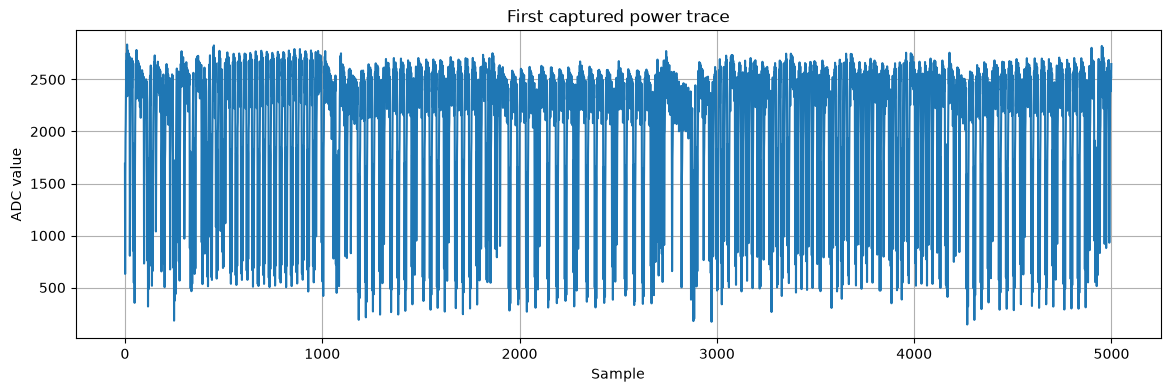

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))
plt.plot(project.traces[0])
plt.xlabel("Sample")
plt.ylabel("ADC value")
plt.title("First captured power trace")
plt.grid(True)
plt.show()

## Create the ChipWhisperer 7 CPA attack
The documented analyzer constructor accepts the project, leakage model and attacked subkeys. set_known_key() enables comparison against the known key for PGE and related results.

In [55]:
attack = cwa.CPA(
    project,
    cwa.leakage_models.sbox_output,
    list(range(16))
)

known_key = np.asarray(project.keys[0], dtype=np.uint8)

attack.set_known_key(known_key)

print("Known key:", known_key.tobytes().hex())

Known key: 2b7e151628aed2a6abf7158809cf4f3c


## Run CPA without a callback
For your checkout, start without a notebook callback. This avoids the API mismatch around

In [57]:
update_interval = max(1, min(10, len(project.traces)))

print("CPA update interval:", update_interval)

attack.run(interval=update_interval)

print("CPA run completed.")

CPA update interval: 10
CPA run completed.


## Verify that CPA generated result history

In [58]:
history = getattr(attack, "sorted_kguesses_hist", None)

if history is None:
    raise RuntimeError(
        "This CPA object does not expose sorted_kguesses_hist."
    )

print("CPA history entries:", len(history))

if len(history) == 0:
    raise RuntimeError(
        "CPA produced no key-guess history. "
        "Verify that the project contains traces and plaintexts, "
        "and that attack.run() completed without an earlier exception."
    )

CPA history entries: 20


## Obtain the recovered key

In [59]:
recovered_key = np.asarray(
    attack.key_guess(),
    dtype=np.uint8
)

print("Known key:    ", known_key.tobytes().hex())
print("Recovered key:", recovered_key.tobytes().hex())
print("Exact match:  ", np.array_equal(recovered_key, known_key))

Known key:     2b7e151628aed2a6abf7158809cf4f3c
Recovered key: 2b7e151628aed2a6abf7158809cf4f3c
Exact match:   True


Show byte-by-byte results

In [60]:
for index, (expected, recovered) in enumerate(
    zip(known_key, recovered_key)
):
    status = "OK" if expected == recovered else "WRONG"

    print(
        f"Byte {index:02d}: "
        f"expected=0x{expected:02X}, "
        f"recovered=0x{recovered:02X} "
        f"{status}"
    )

Byte 00: expected=0x2B, recovered=0x2B OK
Byte 01: expected=0x7E, recovered=0x7E OK
Byte 02: expected=0x15, recovered=0x15 OK
Byte 03: expected=0x16, recovered=0x16 OK
Byte 04: expected=0x28, recovered=0x28 OK
Byte 05: expected=0xAE, recovered=0xAE OK
Byte 06: expected=0xD2, recovered=0xD2 OK
Byte 07: expected=0xA6, recovered=0xA6 OK
Byte 08: expected=0xAB, recovered=0xAB OK
Byte 09: expected=0xF7, recovered=0xF7 OK
Byte 10: expected=0x15, recovered=0x15 OK
Byte 11: expected=0x88, recovered=0x88 OK
Byte 12: expected=0x09, recovered=0x09 OK
Byte 13: expected=0xCF, recovered=0xCF OK
Byte 14: expected=0x4F, recovered=0x4F OK
Byte 15: expected=0x3C, recovered=0x3C OK


In [ ]:
## CPA plots

In [61]:
attack.corr_v_time_plot()

:Overlay
   .Curve.I         :Curve   [x]   (y)
   .Curve.II        :Curve   [x]   (y)
   .Curve.III       :Curve   [x]   (y)
   .Curve.Subkey_0  :Curve   [x]   (y)
   .Curve.IV        :Curve   [x]   (y)
   .Curve.V         :Curve   [x]   (y)
   .Curve.Subkey_1  :Curve   [x]   (y)
   .Curve.VI        :Curve   [x]   (y)
   .Curve.VII       :Curve   [x]   (y)
   .Curve.Subkey_2  :Curve   [x]   (y)
   .Curve.VIII      :Curve   [x]   (y)
   .Curve.IX        :Curve   [x]   (y)
   .Curve.Subkey_3  :Curve   [x]   (y)
   .Curve.X         :Curve   [x]   (y)
   .Curve.XI        :Curve   [x]   (y)
   .Curve.Subkey_4  :Curve   [x]   (y)
   .Curve.XII       :Curve   [x]   (y)
   .Curve.XIII      :Curve   [x]   (y)
   .Curve.Subkey_5  :Curve   [x]   (y)
   .Curve.XIV       :Curve   [x]   (y)
   .Curve.XV        :Curve   [x]   (y)
   .Curve.Subkey_6  :Curve   [x]   (y)
   .Curve.XVI       :Curve   [x]   (y)
   .Curve.XVII      :Curve   [x]   (y)
   .Curve.Subkey_7  :Curve   [x]   (y)
   .Curve.XVIII     :Curve   [x]   (y)
   .Curve.XIX       :Curve   [x]   (y)
   .Curve.Subkey_8  :Curve   [x]   (y)
   .Curve.XX        :Curve   [x]   (y)
   .Curve.XXI       :Curve   [x]   (y)
   .Curve.Subkey_9  :Curve   [x]   (y)
   .Curve.XXII      :Curve   [x]   (y)
   .Curve.XXIII     :Curve   [x]   (y)
   .Curve.Subkey_10 :Curve   [x]   (y)
   .Curve.XXIV      :Curve   [x]   (y)
   .Curve.XXV       :Curve   [x]   (y)
   .Curve.Subkey_11 :Curve   [x]   (y)
   .Curve.XXVI      :Curve   [x]   (y)
   .Curve.XXVII     :Curve   [x]   (y)
   .Curve.Subkey_12 :Curve   [x]   (y)
   .Curve.XXVIII    :Curve   [x]   (y)
   .Curve.XXIX      :Curve   [x]   (y)
   .Curve.Subkey_13 :Curve   [x]   (y)
   .Curve.XXX       :Curve   [x]   (y)
   .Curve.XXXI      :Curve   [x]   (y)
   .Curve.Subkey_14 :Curve   [x]   (y)
   .Curve.XXXII     :Curve   [x]   (y)
   .Curve.XXXIII    :Curve   [x]   (y)
   .Curve.Subkey_15 :Curve   [x]   (y)

In [62]:
attack.pge_v_traces_plot()

:Overlay
   .Curve.I         :Curve   [x]   (y)
   .Curve.Subkey_0  :Curve   [x]   (y)
   .Curve.Subkey_1  :Curve   [x]   (y)
   .Curve.Subkey_2  :Curve   [x]   (y)
   .Curve.Subkey_3  :Curve   [x]   (y)
   .Curve.Subkey_4  :Curve   [x]   (y)
   .Curve.Subkey_5  :Curve   [x]   (y)
   .Curve.Subkey_6  :Curve   [x]   (y)
   .Curve.Subkey_7  :Curve   [x]   (y)
   .Curve.Subkey_8  :Curve   [x]   (y)
   .Curve.Subkey_9  :Curve   [x]   (y)
   .Curve.Subkey_10 :Curve   [x]   (y)
   .Curve.Subkey_11 :Curve   [x]   (y)
   .Curve.Subkey_12 :Curve   [x]   (y)
   .Curve.Subkey_13 :Curve   [x]   (y)
   .Curve.Subkey_14 :Curve   [x]   (y)
   .Curve.Subkey_15 :Curve   [x]   (y)

In [63]:
attack.corr_v_traces_plot()

:Overlay
   .Curve.I         :Curve   [x]   (y)
   .Curve.II        :Curve   [x]   (y)
   .Curve.Subkey_0  :Curve   [x]   (y)
   .Curve.III       :Curve   [x]   (y)
   .Curve.Subkey_1  :Curve   [x]   (y)
   .Curve.IV        :Curve   [x]   (y)
   .Curve.Subkey_2  :Curve   [x]   (y)
   .Curve.V         :Curve   [x]   (y)
   .Curve.Subkey_3  :Curve   [x]   (y)
   .Curve.VI        :Curve   [x]   (y)
   .Curve.Subkey_4  :Curve   [x]   (y)
   .Curve.VII       :Curve   [x]   (y)
   .Curve.Subkey_5  :Curve   [x]   (y)
   .Curve.VIII      :Curve   [x]   (y)
   .Curve.Subkey_6  :Curve   [x]   (y)
   .Curve.IX        :Curve   [x]   (y)
   .Curve.Subkey_7  :Curve   [x]   (y)
   .Curve.X         :Curve   [x]   (y)
   .Curve.Subkey_8  :Curve   [x]   (y)
   .Curve.XI        :Curve   [x]   (y)
   .Curve.Subkey_9  :Curve   [x]   (y)
   .Curve.XII       :Curve   [x]   (y)
   .Curve.Subkey_10 :Curve   [x]   (y)
   .Curve.XIII      :Curve   [x]   (y)
   .Curve.Subkey_11 :Curve   [x]   (y)
   .Curve.XIV       :Curve   [x]   (y)
   .Curve.Subkey_12 :Curve   [x]   (y)
   .Curve.XV        :Curve   [x]   (y)
   .Curve.Subkey_13 :Curve   [x]   (y)
   .Curve.XVI       :Curve   [x]   (y)
   .Curve.Subkey_14 :Curve   [x]   (y)
   .Curve.XVII      :Curve   [x]   (y)
   .Curve.Subkey_15 :Curve   [x]   (y)

In [ ]:
## Optional: attack a smaller sample window
If the AES operation occupies only part of the 5000-sample trace

In [68]:
attack = cwa.CPA(
    project,
    cwa.leakage_models.sbox_output,
    list(range(16))
)

attack.set_known_key(known_key)

attack.set_sample_range(
    start=0,
    stop=5000
)

attack.run(
    interval=max(1, min(10, len(project.traces)))
)

if len(attack.sorted_kguesses_hist) == 0:
    raise RuntimeError("CPA did not generate key-guess results.")

print(bytes(attack.key_guess()).hex())

2b7e151628aed2a6abf7158809cf4f3c


## Optional: callback detected from your checkout

The CPA does not require a callback. If you want a live result table, detect only names that actually exist

In [70]:
callback = None
if hasattr(cwa, "get_table_cb"):
    callback = cwa.get_table_cb()
    print("Using get_table_cb")
elif hasattr(cwa, "get_jupyter_cb"):
    callback = cwa.get_jupyter_cb()
    print("Using get_jupyter_cb")
else:
     print("No supported notebook callback found; running without one.")
 
attack = cwa.CPA( project, cwa.leakage_models.sbox_output, list(range(16)))
     
attack.set_known_key(known_key)
     
attack.run( interval=max(1, min(10, len(project.traces))), callback=callback)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
PGE=,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,2B-0.881,7E-0.900,15-0.897,16-0.890,28-0.867,AE-0.889,D2-0.887,A6-0.879,AB-0.909,F7-0.870,15-0.893,88-0.915,09-0.904,CF-0.895,4F-0.905,3C-0.887
1,5D0.324,C2-0.337,5F0.339,680.336,3E-0.353,64-0.357,A80.389,F40.371,CD-0.348,C40.337,06-0.350,380.342,C30.353,57-0.359,4C-0.356,AE-0.348
2,2E0.321,D2-0.337,690.339,190.330,BE0.341,BA0.330,AC-0.345,BF-0.329,3F0.347,6E-0.336,93-0.342,010.334,D60.346,E80.334,EF0.353,49-0.332
3,46-0.314,570.329,580.326,B10.322,71-0.329,370.328,13-0.337,52-0.323,390.341,BF-0.335,2A0.338,8F-0.330,30-0.332,010.333,5C0.337,59-0.327
4,0A0.311,EE-0.323,E50.324,640.321,52-0.323,0E0.327,4D-0.332,9B-0.318,5A-0.339,3D0.330,A50.335,B80.329,350.327,3A0.324,2B0.336,C0-0.326


## Optional: save and reopen the project

In [71]:
project.save("Lab_4_3_CW7.zip")

reopen and check

In [72]:
projectReload = cw.open_project("Lab_4_3_CW7.zip")
print(projectReload)
print(projectReload.traces.shape)

len         = 200
size        = 200
traces = 
    exists = 1
    len    = (5000,)
    dtype  = int16
plaintexts = 
    exists = 1
    len    = (16,)
    dtype  = uint8
ciphertexts = 
    exists = 1
    len    = (16,)
    dtype  = uint8
keys = 
    exists = 1
    len    = (16,)
    dtype  = uint8

(200, 5000)


## Minimal corrected Lab 4_3 block

In [75]:
import numpy as np
import chipwhisperer as cw
import chipwhisperer.analyzer as cwa
from tqdm.notebook import trange

NUMBER_OF_TRACES = 200

# Capture
project = cw.Project(init_size=NUMBER_OF_TRACES)
ktp = cw.ktp.Basic()

key, _ = ktp.next()
key = bytearray(key)

target.flush()

for _ in trange(NUMBER_OF_TRACES):
    _, plaintext = ktp.next()

    trace = cw.capture_trace(
        scope,
        target,
        plaintext,
        key
    )

    if trace is None:
        target.flush()
        continue

    project.append(trace)

if len(project.traces) == 0:
    raise RuntimeError("No traces were captured.")

print("Trace data:", project.traces.shape)
print("Plaintexts:", project.plaintexts.shape)
print("Keys:", project.keys.shape)

# CPA
known_key = np.asarray(project.keys[0], dtype=np.uint8)

attack = cwa.CPA(
    project,
    cwa.leakage_models.sbox_output,
    list(range(16))
)

attack.set_known_key(known_key)

attack.run(
    interval=max(1, min(10, len(project.traces)))
)

# Results
if len(attack.sorted_kguesses_hist) == 0:
    raise RuntimeError(
        "CPA completed without generating key-guess history."
    )

recovered_key = np.asarray(attack.key_guess(), dtype=np.uint8)

print("Known:    ", known_key.tobytes().hex())
print("Recovered:", recovered_key.tobytes().hex())
print("Match:    ", np.array_equal(known_key, recovered_key))


  0%|          | 0/200 [00:00<?, ?it/s]

Trace data: (200, 5000)
Plaintexts: (200, 16)
Keys: (200, 16)
Known:     2b7e151628aed2a6abf7158809cf4f3c
Recovered: 2b7e151628aed2a6abf7158809cf4f3c
Match:     True


In [6]:
SCOPETYPE = 'OPENADC'
PLATFORM = 'CWHUSKY'
CRYPTO_TARGET='TINYAES128C' 
SS_VER='SS_VER_2_1'
VERSION = 'HARDWARE'

if VERSION == 'HARDWARE':
    %run "Lab 4_3 - ChipWhisperer Analyzer CPA Attack (HARDWARE).ipynb"
elif VERSION == 'SIMULATED':
    %run "Lab 4_3 - ChipWhisperer Analyzer CPA Attack (SIMULATED).ipynb"

INFO: Found ChipWhisperer😍
Building for platform CWHUSKY with CRYPTO_TARGET=TINYAES128C
SS_VER set to SS_VER_2_1
SS_VER set to SS_VER_2_1
Blank crypto options, building for AES128
arm-none-eabi-gcc (15:14.2.rel1-1) 14.2.1 20241119
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWHUSKY 
.
Welcome to another exciting ChipWhisperer target build!!
.
.
.
Compiling:
Compiling:
.
.
Compiling:
-en     simpleserial-aes.c ...
-en     .././simpleserial/simpleserial.c ...
Compiling:
Compiling:
-en     .././hal/hal.c ...
-en     .././hal//sam4s/startup_sam4s.c ...
-en     .././hal//sam4s/sam4s_hal.c ...
.
.
Compiling:
.
Compiling:
-en     .././hal//sam4s/uart.c ...
Compiling:
.
-en     .././hal//sam4s/pio.c ...
-en     .././hal//sam4s/system_sam4s.c ...
Compiling:
-en     .././hal//sam4s/sysclk.c ...
.
.
Compiling:
.
Compiling:
-e

Capturing traces:   0%|          | 0/50 [00:00<?, ?it/s]

Before we continue on with our CPA attack, let's take a quick look at the projects:

In [11]:
# we can access wave, textin, etc as a whole with proj.traces
for trace in proj.traces:
    #print(trace.trace[0], trace.textin, trace.textout, trace.key)
    print( proj.traces[i][0], proj.plaintexts[i], proj.ciphertexts[i], proj.keys[i] )

# can also access individually with proj.waves, proj.textins, etc.
for wave in proj.traces:
    print(wave[0])

1700 [  1 251 238 102 186 179  79 180 102 200 166  31 208 221 101   1] [159 116 236  12 115 119 198 149  85  74 134 238  49 208 222 167] [ 43 126  21  22  40 174 210 166 171 247  21 136   9 207  79  60]
1700 [  1 251 238 102 186 179  79 180 102 200 166  31 208 221 101   1] [159 116 236  12 115 119 198 149  85  74 134 238  49 208 222 167] [ 43 126  21  22  40 174 210 166 171 247  21 136   9 207  79  60]
1700 [  1 251 238 102 186 179  79 180 102 200 166  31 208 221 101   1] [159 116 236  12 115 119 198 149  85  74 134 238  49 208 222 167] [ 43 126  21  22  40 174 210 166 171 247  21 136   9 207  79  60]
1700 [  1 251 238 102 186 179  79 180 102 200 166  31 208 221 101   1] [159 116 236  12 115 119 198 149  85  74 134 238  49 208 222 167] [ 43 126  21  22  40 174 210 166 171 247  21 136   9 207  79  60]
1700 [  1 251 238 102 186 179  79 180 102 200 166  31 208 221 101   1] [159 116 236  12 115 119 198 149  85  74 134 238  49 208 222 167] [ 43 126  21  22  40 174 210 166 171 247  21 136   

## Reporting Intervals
When we ran attack.run(), we processed all of the traces before getting any information back. ChipWhisperer Analyzer actually uses the "online" correlation calculation that we mentioned last time, meaning we can get feedback during the attack. This can be done by creating a callback function and passing it to attack.run(). This function is called each time we pass the update interval (default 25, which is the second parameter for attack.run()).

Let's use this to update our table every 10 traces. Most of this is just putting our existing code into the callback function. We also need use the clear_output function to clear the table, as well as display() to actually get it to show up:

In [77]:
import chipwhisperer as cw
cb = cwa.get_table_cb()
results = attack.run(interval=10, callback=cb)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
PGE=,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,2B-0.913,7E-0.898,15-0.900,16-0.887,28-0.910,AE-0.898,D2-0.879,A6-0.901,AB-0.894,F7-0.916,15-0.893,88-0.901,09-0.902,CF-0.899,4F-0.884,3C-0.877
1,94-0.374,410.395,100.334,800.334,A20.340,840.353,B0-0.346,860.334,3A-0.354,AF-0.382,9A-0.342,0A0.349,94-0.451,880.350,F2-0.342,FA-0.374
2,6F-0.338,74-0.363,8B0.329,AA0.331,AB-0.338,0B0.332,30-0.343,60-0.332,D50.349,E5-0.364,5C0.327,890.320,A8-0.344,96-0.339,19-0.338,C90.322
3,AA-0.326,130.354,B00.329,B60.329,C1-0.333,6A-0.325,0E-0.325,CC0.327,5B0.339,1A0.349,310.316,610.319,72-0.342,22-0.331,2C-0.330,E00.319
4,930.326,88-0.353,17-0.326,2B-0.326,230.332,590.318,FF-0.321,6E-0.323,9B-0.328,DA-0.333,F0-0.313,17-0.316,53-0.342,53-0.322,E40.328,FC-0.315


## Plot Data
Analyzer also includes a module to create plots to help you interpret the data. These act on one subkey at a time and return some data that we can plot using bokeh (or your graphing module of choice). Let's start by grabbing the class that does all the calculations:

inspect the complete public API

In [80]:
print("\n--- attack ---")
for x in dir(attack):
    if not x.startswith("_"):
        print(x)



--- attack ---
avg_pge
best_corrs
calculate_correlation
corr_v_time
corr_v_time_plot
corr_v_traces
corr_v_traces_plot
correlations
ct_array
from_cpa
from_zarr
gen_hyp
h2_sum
highest_corr_v_time
highest_corr_v_traces
hsum
hyp_array
key_guess
key_recovered
kguess_corrs
kguesses
known_key
leakage_model
lowest_corr_v_time
lowest_corr_v_traces
max_corr_loc
max_corr_location
max_correlations_hist
num_traces
pge
pge_v_traces
pge_v_traces_plot
project
pt_array
reset
run
save_results
save_zip
set_known_key
set_leakage_model
set_sample_range
set_trace_range
sort_and_rank
sorted_kguesses_hist
subkeys
t2_sum
th_sum
trace_array
trace_len
traces_used
traces_used_hist
tsum
update_state

--- results ---
